## Configuracion

En este primer bloque dejamos listo todo lo que vamos a necesitar en el cuaderno:
* Importamos las librerias para manejar tablas, hacer calculos, dibujar graficas, reducir dimensiones con PCA y montar redes neuronales con Keras.
* Ajustamos el tamaño de las graficas y hacemos que pandas enseñe todas las columnas sin cortarlas.
* Guardamos en variables la ruta del archivo `sample.csv`, los nombres de las columnas que nos interesan y una semilla fija para que al ejecutar el codigo siempre nos salgan los mismos resultados.

In [12]:
# importamos las librerias para manejar rutas del sistema, tablas y matematicas
import os
import pandas as pd
import numpy as np

# importamos las librerias para hacer los graficos
import matplotlib.pyplot as plt
import seaborn as sns

# importamos las herramientas de machine learning y redes neuronales
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Flatten, Dense, Dropout

# hacemos que pandas muestre todas las columnas de la tabla y damos estilo a las graficas
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# ponemos una semilla fija para que los resultados aleatorios salgan siempre igual
semilla_aleatoria = 42

# guardamos donde esta nuestro archivo csv con los datos
carpeta_datos = "datos"
ruta_archivo_csv = os.path.join(carpeta_datos, "sample.csv")

# guardamos los nombres de las columnas importantes del ejercicio en variables
columna_fecha_recogida = "pickup_datetime"
columna_fecha_llegada = "dropoff_datetime"
columna_zona_recogida = "PULocationID"
columna_zona_destino = "DOLocationID"

# miramos si el archivo existe en la carpeta para no tener fallos al cargarlo luego
if os.path.exists(ruta_archivo_csv):
    print(f"Archivo encontrado en: {ruta_archivo_csv}")
else:
    print(f"No se encuentra el archivo en {ruta_archivo_csv}, revisa la carpeta datos")

Archivo encontrado en: datos/sample.csv


## 1. Carga de datos y primera revision

Ahora vamos a leer el archivo `sample.csv` con `pandas` para ver como vienen los datos antes de tocar nada. 

En este paso buscamos comprobar:
* Cuantas filas (viajes) y columnas tiene la tabla en total.
* Como son las primeras filas y que tipo de dato tiene cada columna (para saber si las fechas se han guardado como texto o si las zonas son numeros enteros).
* Cuantos valores nulos (casillas vacias) hay en cada columna para decidir luego como limpiarlos.

In [13]:
# leemos el archivo csv y lo guardamos en nuestra tabla principal
tabla_viajes_taxis = pd.read_csv(ruta_archivo_csv)

# sacamos cuantas filas y columnas tiene la tabla
numero_filas, numero_columnas = tabla_viajes_taxis.shape
print(f"Total de viajes (filas): {numero_filas}")
print(f"Total de variables (columnas): {numero_columnas}\n")

# enseñamos las primeras 5 filas para ver que pinta tienen los datos
print("--- Primeras 5 filas de la tabla ---")
display(tabla_viajes_taxis.head())

# miramos de que tipo es cada columna (texto, numero entero, decimal...)
print("\n--- Tipos de datos de cada columna ---")
print(tabla_viajes_taxis.dtypes)

# contamos cuantos valores vacios (nulos) hay en cada columna y sacamos el porcentaje
conteo_valores_nulos = tabla_viajes_taxis.isnull().sum()
porcentaje_valores_nulos = (conteo_valores_nulos / numero_filas) * 100

# juntamos la cantidad y el porcentaje en una tabla pequeña para verlo mas claro
tabla_resumen_nulos = pd.DataFrame({
    "cantidad_nulos": conteo_valores_nulos,
    "porcentaje_nulos": porcentaje_valores_nulos.round(2)
})

print("\n--- Resumen de valores nulos por columna ---")
display(tabla_resumen_nulos)

Total de viajes (filas): 200000
Total de variables (columnas): 7

--- Primeras 5 filas de la tabla ---


,hvfhs_license_num,dispatching_base_num,pickup_datetime,dropoff_datetime,PULocationID,DOLocationID,SR_Flag
0,HV0005,B02510,02/12/2019 11:10:30 AM,02/12/2019 11:19:14 AM,80,112,NaN
1,HV0005,B02510,02/12/2019 11:35:27 AM,02/12/2019 11:54:29 AM,256,125,NaN
2,HV0003,B02867,02/12/2019 11:03:14 AM,02/12/2019 11:21:04 AM,210,155,1.0
3,HV0003,B02867,02/12/2019 11:12:12 AM,02/12/2019 11:24:40 AM,155,155,1.0
4,HV0003,B02867,02/12/2019 11:50:05 AM,02/12/2019 11:59:14 AM,155,91,NaN



--- Tipos de datos de cada columna ---
hvfhs_license_num           str
dispatching_base_num        str
pickup_datetime             str
dropoff_datetime            str
PULocationID              int64
DOLocationID              int64
SR_Flag                 float64
dtype: object

--- Resumen de valores nulos por columna ---


,cantidad_nulos,porcentaje_nulos
hvfhs_license_num,0,0.00
dispatching_base_num,3,0.00
pickup_datetime,0,0.00
dropoff_datetime,0,0.00
PULocationID,0,0.00
DOLocationID,0,0.00
SR_Flag,156424,78.21


## 2. Limpieza de nulos y calculo de la duracion del viaje

En este paso vamos a preparar los datos para que el modelo pueda entenderlos:
* Borramos las 3 filas que tienen vacia la base de despacho (`dispatching_base_num`), ya que al ser poquísimas no afectan en nada.
* Convertimos las columnas de fecha de recogida y llegada de texto plano a formato fecha real de Python, entendiendo las horas y el formato AM/PM.
* Restamos la hora de llegada menos la de salida para obtener la **duracion del viaje** (nuestro objetivo o *target*), pasandola a minutos para que sea facil de analizar.
* Echamos un vistazo rapido para comprobar que no queden valores extraños (como viajes que duren 0 minutos o tiempos negativos imposibles).

In [14]:
# quitamos las 3 filas que no tienen base de despacho porque son poquisimas y no afectan
columna_base_despacho = "dispatching_base_num"
tabla_viajes_taxis = tabla_viajes_taxis.dropna(subset=[columna_base_despacho])

# pasamos las fechas de texto normal a formato fecha de verdad para poder hacer cuentas con ellas
tabla_viajes_taxis[columna_fecha_recogida] = pd.to_datetime(tabla_viajes_taxis[columna_fecha_recogida])
tabla_viajes_taxis[columna_fecha_llegada] = pd.to_datetime(tabla_viajes_taxis[columna_fecha_llegada])

# restamos la hora de llegada menos la de salida y lo pasamos a minutos
tabla_viajes_taxis["duracion_minutos"] = (
    tabla_viajes_taxis[columna_fecha_llegada] - tabla_viajes_taxis[columna_fecha_recogida]
).dt.total_seconds() / 60

# sacamos un resumen con la media, el minimo y el maximo para ver si hay tiempos raros
print("--- Resumen de la duracion de los viajes en minutos ---")
print(tabla_viajes_taxis["duracion_minutos"].describe())

# comprobamos cuantas filas nos quedan ahora
print(f"\nFilas totales despues de limpiar: {len(tabla_viajes_taxis)}")

--- Resumen de la duracion de los viajes en minutos ---
count    199997.000000
mean         18.842240
std          13.039329
min           0.000000
25%           9.600000
50%          15.533333
75%          24.550000
max         371.466667
Name: duracion_minutos, dtype: float64

Filas totales despues de limpiar: 199997


### Conclusiones de los datos obtenidos

Al revisar el resumen de la duracion de los viajes vemos que la mayoria son trayectos urbanos normales: la media es de unos 19 minutos y la mitad de los viajes duran entre 9 y 25 minutos.

Sin embargo, hemos detectado dos detalles que tenemos que arreglar antes de seguir:
* Hay viajes con duracion de **0 minutos** (posibles cancelaciones o fallos del sistema) y viajes extremos de hasta **371 minutos** (mas de 6 horas), que son valores atipicos que pueden confundir al modelo.
* Todavia nos queda por resolver los nulos de la columna `SR_Flag` (el 78% de los datos), donde un hueco vacio significa simplemente que el viaje no fue compartido.

**Siguiente paso:** Vamos a rellenar los nulos de `SR_Flag` con un `0` (viaje normal) y a revisar cuantos viajes tienen duraciones absurdas (por ejemplo, menos de 1 minuto o mas de 2 horas) para limpiarlos y dejar la tabla lista para los histogramas.

## 3. Resolucion de nulos en SR_Flag y revision de duraciones raras

Ahora vamos a terminar con los valores nulos y a revisar los casos extremos de duracion:
* Rellenamos los huecos vacios de `SR_Flag` con un `0` (viaje normal no compartido) y pasamos la columna a numero entero para que quede limpia.
* Comprobamos que ya no quede ningun valor nulo en toda la tabla.
* Contamos cuantos viajes duran menos de 1 minuto o mas de 2 horas (120 minutos) para ver cuantos errores o casos extremos tenemos antes de filtrarlos.

In [15]:
# guardamos el nombre de la columna de viaje compartido en una variable
columna_viaje_compartido = "SR_Flag"

# rellenamos los huecos vacios con 0 porque significan que el viaje no fue compartido y lo pasamos a entero
tabla_viajes_taxis[columna_viaje_compartido] = tabla_viajes_taxis[columna_viaje_compartido].fillna(0).astype(int)

# comprobamos que ya no queda ningun valor nulo en ninguna columna
print("--- Comprobacion de nulos despues de limpiar ---")
print(tabla_viajes_taxis.isnull().sum())

# contamos cuantos viajes son demasiado cortos (menos de 1 minuto) o demasiado largos (mas de 2 horas)
viajes_muy_cortos = (tabla_viajes_taxis["duracion_minutos"] < 1).sum()
viajes_muy_largos = (tabla_viajes_taxis["duracion_minutos"] > 120).sum()

print(f"\nViajes de menos de 1 minuto: {viajes_muy_cortos}")
print(f"Viajes de mas de 120 minutos (2 horas): {viajes_muy_largos}")

--- Comprobacion de nulos despues de limpiar ---
hvfhs_license_num       0
dispatching_base_num    0
pickup_datetime         0
dropoff_datetime        0
PULocationID            0
DOLocationID            0
SR_Flag                 0
duracion_minutos        0
dtype: int64

Viajes de menos de 1 minuto: 77
Viajes de mas de 120 minutos (2 horas): 60


### Conclusiones de la limpieza

Ya no queda ningun valor nulo en toda la tabla. Ademas, al revisar los tiempos raros hemos visto que solo hay 77 viajes de menos de 1 minuto y 60 de mas de 2 horas (137 viajes en total de casi 200.000). 

Como son poquisimos, vamos a eliminarlos para quedarnos solo con trayectos urbanos normales y reales.

**Siguiente paso:** Filtraremos esos 137 viajes extremos y pasaremos al punto 2 del ejercicio: dibujar los histogramas de las zonas de recogida (`PULocationID`) y de destino (`DOLocationID`) para ver como se reparten los viajes por Nueva York y comprobar si hay zonas con muy pocos viajes que nos convenga juntar en una categoria generica.

## 4. Filtrado de viajes extremos e histogramas de zonas

Primero quitamos los 137 viajes con duraciones imposibles o demasiado largas (nos quedamos solo con viajes entre 1 y 120 minutos).

Despues, dibujamos dos histogramas: uno para las zonas donde suben los pasajeros (`PULocationID`) y otro para las zonas donde bajan (`DOLocationID`). Tambien vamos a mirar cuantas zonas distintas hay y cuales son las que menos viajes tienen, para decidir si merece la pena agrupar las mas raras en una sola categoria.

Viajes finales despues de quitar los extremos: 199860

Total de zonas de recogida distintas: 260
Total de zonas de destino distintas: 260

--- Las 10 zonas de RECOGIDA con menos viajes ---
PULocationID
154    10
207     9
253     8
8       6
111     6
99      5
30      4
27      2
2       1
110     1
Name: count, dtype: int64

--- Las 10 zonas de DESTINO con menos viajes ---
DOLocationID
120    19
207    13
253     9
111     8
8       7
30      4
27      3
99      3
2       1
105     1
Name: count, dtype: int64


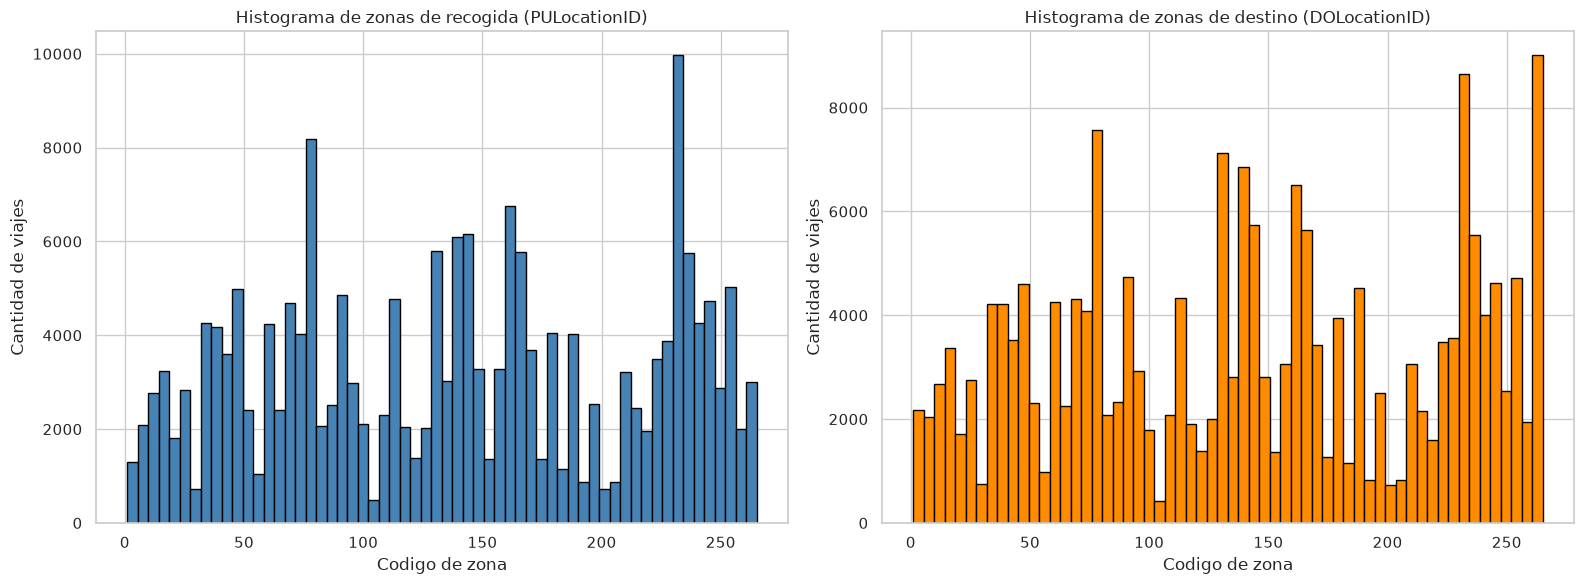

In [16]:
# nos quedamos solo con los viajes normales que duran entre 1 minuto y 2 horas
filtro_duracion_normal = (tabla_viajes_taxis["duracion_minutos"] >= 1) & (tabla_viajes_taxis["duracion_minutos"] <= 120)
tabla_viajes_taxis = tabla_viajes_taxis[filtro_duracion_normal].copy()

print(f"Viajes finales despues de quitar los extremos: {len(tabla_viajes_taxis)}\n")

# contamos cuantos viajes tiene cada zona de recogida y de destino
conteo_zonas_recogida = tabla_viajes_taxis[columna_zona_recogida].value_counts()
conteo_zonas_destino = tabla_viajes_taxis[columna_zona_destino].value_counts()

print(f"Total de zonas de recogida distintas: {len(conteo_zonas_recogida)}")
print(f"Total de zonas de destino distintas: {len(conteo_zonas_destino)}\n")

# enseñamos las 10 zonas con menos viajes para ver si hay categorias casi vacias
print("--- Las 10 zonas de RECOGIDA con menos viajes ---")
print(conteo_zonas_recogida.tail(10))

print("\n--- Las 10 zonas de DESTINO con menos viajes ---")
print(conteo_zonas_destino.tail(10))

# preparamos dos graficas una al lado de la otra para ver los histogramas
figura, ejes = plt.subplots(1, 2, figsize=(16, 6))

# histograma de la zona de recogida
ejes[0].hist(tabla_viajes_taxis[columna_zona_recogida], bins=60, color="steelblue", edgecolor="black")
ejes[0].set_title("Histograma de zonas de recogida (PULocationID)")
ejes[0].set_xlabel("Codigo de zona")
ejes[0].set_ylabel("Cantidad de viajes")

# histograma de la zona de destino
ejes[1].hist(tabla_viajes_taxis[columna_zona_destino], bins=60, color="darkorange", edgecolor="black")
ejes[1].set_title("Histograma de zonas de destino (DOLocationID)")
ejes[1].set_xlabel("Codigo de zona")
ejes[1].set_ylabel("Cantidad de viajes")

plt.tight_layout()
plt.show()

## 5. Agrupacion de zonas poco frecuentes

Vamos a buscar que zonas de recogida y de destino tienen menos de 100 viajes en total y las vamos a juntar todas bajo el codigo `0` (nuestra categoria generica de "Otras zonas"). Luego comprobaremos cuantas zonas distintas nos quedan para preparar los embeddings.

In [17]:
# fijamos el minimo de viajes que necesita una zona para mantener su propio codigo
minimo_viajes_zona = 100
codigo_zona_generica = 0

# sacamos la lista de zonas que no llegan al minimo de viajes
zonas_recogida_raras = conteo_zonas_recogida[conteo_zonas_recogida < minimo_viajes_zona].index
zonas_destino_raras = conteo_zonas_destino[conteo_zonas_destino < minimo_viajes_zona].index

print(f"Zonas de recogida con menos de {minimo_viajes_zona} viajes: {len(zonas_recogida_raras)}")
print(f"Zonas de destino con menos de {minimo_viajes_zona} viajes: {len(zonas_destino_raras)}")

# cambiamos el codigo de esas zonas raras por el 0 en la tabla
tabla_viajes_taxis[columna_zona_recogida] = tabla_viajes_taxis[columna_zona_recogida].replace(zonas_recogida_raras, codigo_zona_generica)
tabla_viajes_taxis[columna_zona_destino] = tabla_viajes_taxis[columna_zona_destino].replace(zonas_destino_raras, codigo_zona_generica)

# miramos cuantas zonas distintas nos quedan al final en cada columna
print(f"\nTotal de zonas de recogida finales: {tabla_viajes_taxis[columna_zona_recogida].nunique()}")
print(f"Total de zonas de destino finales: {tabla_viajes_taxis[columna_zona_destino].nunique()}")

Zonas de recogida con menos de 100 viajes: 37
Zonas de destino con menos de 100 viajes: 34

Total de zonas de recogida finales: 224
Total de zonas de destino finales: 227


### Conclusiones de la agrupacion de zonas

Hemos juntado 37 zonas de recogida y 34 zonas de destino que tenian menos de 100 viajes dentro de la categoria generica `0`. Ahora nos quedamos con 224 zonas de recogida y 227 zonas de destino bien representadas.

**Siguiente paso:** Pasamos a codificar las zonas con `LabelEncoder` para numerarlas seguidas desde el `0` sin huecos, y crearemos una clase para entrenar dos redes neuronales independientes (una para recogida y otra para destino).

## 6. Codificacion de las zonas para la red neuronal

La capa `Embedding` necesita que las categorias sean numeros enteros seguidos empezando desde el `0` sin saltos. Usamos `LabelEncoder` en las columnas de recogida y destino, y guardamos el resultado en columnas nuevas para no perder los codigos reales de Nueva York.

In [18]:
# preparamos los codificadores para que las zonas vayan seguidas desde el 0 sin huecos
codificador_recogida = LabelEncoder()
codificador_destino = LabelEncoder()

# transformamos las dos columnas y las guardamos aparte para no perder los codigos originales
tabla_viajes_taxis["zona_recogida_codificada"] = codificador_recogida.fit_transform(tabla_viajes_taxis[columna_zona_recogida])
tabla_viajes_taxis["zona_destino_codificada"] = codificador_destino.fit_transform(tabla_viajes_taxis[columna_zona_destino])

# contamos cuantas zonas distintas tiene cada columna
cantidad_zonas_recogida = tabla_viajes_taxis["zona_recogida_codificada"].nunique()
cantidad_zonas_destino = tabla_viajes_taxis["zona_destino_codificada"].nunique()

print(f"Categorias listas -> Recogida: {cantidad_zonas_recogida} | Destino: {cantidad_zonas_destino}")

Categorias listas -> Recogida: 224 | Destino: 227


## 7. Creacion de la clase ModeloEntrenamiento

Creamos una clase para que sea nuestro modelo de aprendizaje en ambas situaciones (recogida y destino) y ahorrarnos repetir codigo. Definimos la estructura de la red neuronal una sola vez y despues crearemos dos instancias independientes.

Ajustamos el tamaño del embedding a `4` dimensiones para no meter demasiadas columnas que puedan provocar sobreajuste, y reservamos un 20% de los datos para validacion (`validation_split=0.2`) para comprobar si la red generaliza bien.

In [19]:
# clase que sirve de molde para montar y entrenar cada red neuronal por separado
class ModeloEntrenamiento:
    def __init__(self, cantidad_categorias, tamano_embedding=4):
        # guardamos cuantas zonas entran y cuantas dimensiones tendra el embedding
        self.cantidad_categorias = cantidad_categorias
        self.tamano_embedding = tamano_embedding

        # montamos las capas de la red neuronal una detras de otra
        self.red = Sequential()
        self.red.add(Embedding(input_dim=self.cantidad_categorias, output_dim=self.tamano_embedding, name="capa_embedding"))
        self.red.add(Flatten())
        self.red.add(Dense(64, activation="relu"))
        self.red.add(Dropout(0.3))
        self.red.add(Dense(1, activation="relu"))

        # configuramos el optimizador y el error medio absoluto en minutos
        self.red.compile(optimizer="adam", loss="mean_absolute_error", metrics=["mae"])

    def entrenar(self, entrada, objetivo, tamano_lote=256, epocas=5):
        # entrenamos la red apartando un 20% de los datos para ver si hay sobreajuste
        return self.red.fit(
            entrada,
            objetivo,
            batch_size=tamano_lote,
            epochs=epocas,
            validation_split=0.2,
            verbose=1
        )

    def obtener_embeddings(self):
        # devolvemos la tabla de pesos aprendidos de la capa de embedding
        return self.red.get_layer("capa_embedding").get_weights()[0]

## 8. Entrenamiento de las dos redes neuronales (Recogida y Destino)

Ahora creamos dos instancias independientes a partir de nuestra clase `ModeloEntrenamiento`: una aprende a predecir la duracion del viaje usando solo la zona de recogida (`PULocationID`) y la otra usando solo la zona de destino (`DOLocationID`).

In [20]:
# separamos las entradas y la salida que queremos predecir
entrada_recogida = tabla_viajes_taxis["zona_recogida_codificada"]
entrada_destino = tabla_viajes_taxis["zona_destino_codificada"]
objetivo_duracion = tabla_viajes_taxis["duracion_minutos"]

# creamos las dos instancias independientes de nuestra clase
modelo_recogida = ModeloEntrenamiento(cantidad_categorias=cantidad_zonas_recogida, tamano_embedding=4)
modelo_destino = ModeloEntrenamiento(cantidad_categorias=cantidad_zonas_destino, tamano_embedding=4)

# entrenamos el modelo de recogida
print("--- Entrenando red de zonas de recogida ---")
historial_recogida = modelo_recogida.entrenar(entrada_recogida, objetivo_duracion)

# entrenamos el modelo de destino
print("\n--- Entrenando red de zonas de destino ---")
historial_destino = modelo_destino.entrenar(entrada_destino, objetivo_duracion)

--- Entrenando red de zonas de recogida ---
Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 10.9454 - mae: 10.9454 - val_loss: 9.7878 - val_mae: 9.7878
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 8.7061 - mae: 8.7061 - val_loss: 9.7744 - val_mae: 9.7744
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 8.7028 - mae: 8.7028 - val_loss: 9.7756 - val_mae: 9.7756
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 8.7042 - mae: 8.7042 - val_loss: 9.7716 - val_mae: 9.7716
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 8.7017 - mae: 8.7017 - val_loss: 9.7669 - val_mae: 9.7669

--- Entrenando red de zonas de destino ---
Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 10.6282 - mae: 10.6282 - val_loss: 9.7548 - val_mae: 9.7548
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 8.4225 - mae: 8.4225 - val_loss: 9.7198 - val_mae: 9.7198
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 8.4180 - mae: 8.4180 - val_los

### Conclusiones del entrenamiento de las dos redes

Las dos redes neuronales han entrenado muy rapido y de forma estable con 4 dimensiones de embedding:
* **Zona de recogida (`PULocationID`):** el error medio (`mae`) baja hasta **8,70 minutos** en entrenamiento y **9,77 minutos** en validacion (`val_mae`).
* **Zona de destino (`DOLocationID`):** el error medio baja hasta **8,42 minutos** en entrenamiento y **9,70 minutos** en validacion.

En los dos casos el error de validacion se mantiene estable y no empieza a subir con las epocas, lo que confirma que la red **no esta sufriendo sobreajuste**.

**Siguiente paso:** Extraemos los embeddings de 4 dimensiones que ha aprendido cada red y los reducimos a 2 dimensiones con PCA para poder dibujarlos y buscar zonas anomalas.

## 9. Reduccion de dimensionalidad con PCA y visualizacion en 2D

En este paso extraemos los vectores de embeddings que han aprendido las dos redes neuronales y los reducimos de 4 dimensiones a 2 usando `PCA`.

Despues dibujamos dos graficos de dispersion (uno para zonas de recogida y otro para zonas de destino) para observar si se forman grupos de zonas parecidas o si hay categorias que se quedan muy aisladas del resto. Para poder identificarlas luego, etiquetamos en el grafico las 5 zonas que quedan mas alejadas del centro.

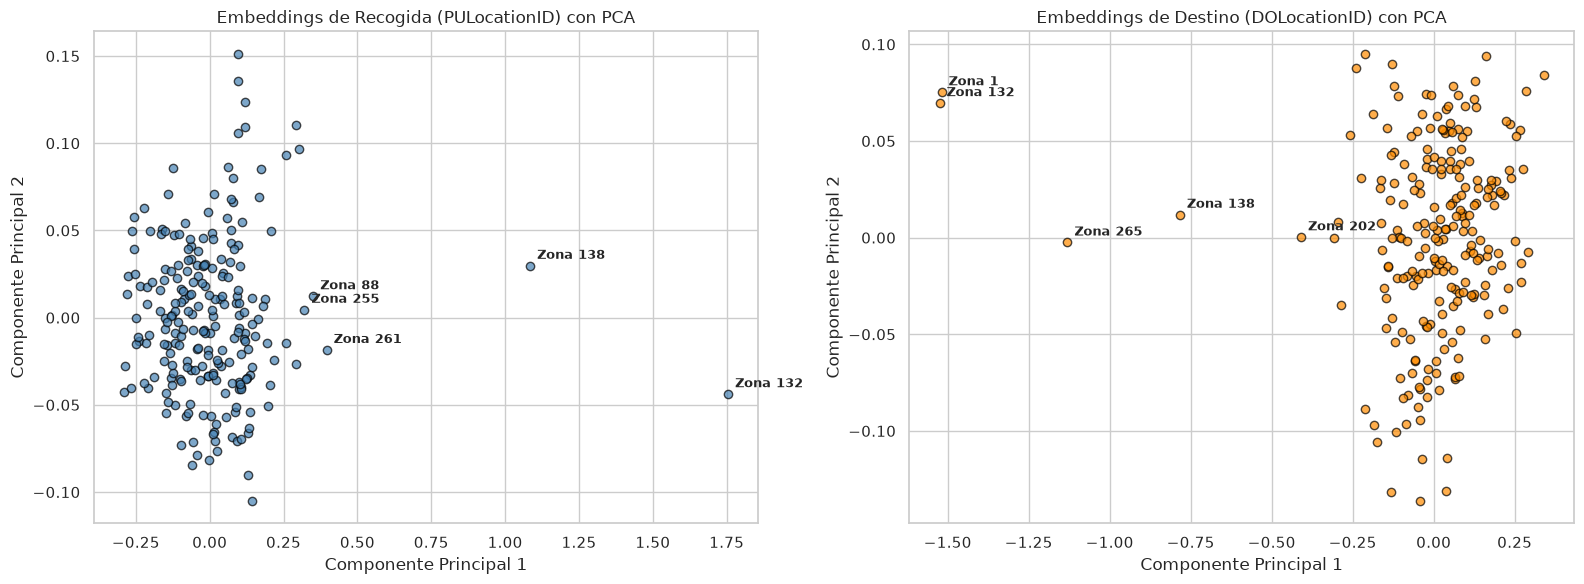

In [21]:
# sacamos los pesos (los vectores de 4 numeros) de cada capa de embedding
embeddings_recogida = modelo_recogida.obtener_embeddings()
embeddings_destino = modelo_destino.obtener_embeddings()

# aplicamos PCA para bajar de 4 dimensiones a 2 y poder dibujarlos en un plano
pca_recogida = PCA(n_components=2, random_state=semilla_aleatoria).fit_transform(embeddings_recogida)
pca_destino = PCA(n_components=2, random_state=semilla_aleatoria).fit_transform(embeddings_destino)

# recuperamos los codigos reales de las zonas de Nueva York para saber quien es cada punto
codigos_reales_recogida = codificador_recogida.inverse_transform(range(cantidad_zonas_recogida))
codigos_reales_destino = codificador_destino.inverse_transform(range(cantidad_zonas_destino))

# calculamos la distancia de cada punto al centro (0,0) para encontrar los 5 mas alejados
distancias_recogida = np.sqrt(pca_recogida[:, 0]**2 + pca_recogida[:, 1]**2)
indices_extremos_recogida = np.argsort(distancias_recogida)[-5:]

distancias_destino = np.sqrt(pca_destino[:, 0]**2 + pca_destino[:, 1]**2)
indices_extremos_destino = np.argsort(distancias_destino)[-5:]

# dibujamos las dos graficas de puntos una al lado de la otra
figura, ejes = plt.subplots(1, 2, figsize=(16, 6))

# grafica de zonas de recogida
ejes[0].scatter(pca_recogida[:, 0], pca_recogida[:, 1], alpha=0.7, color="steelblue", edgecolors="black")
ejes[0].set_title("Embeddings de Recogida (PULocationID) con PCA")
ejes[0].set_xlabel("Componente Principal 1")
ejes[0].set_ylabel("Componente Principal 2")

# ponemos el numero de zona real a los 5 puntos mas extremos de recogida
for indice in indices_extremos_recogida:
    ejes[0].annotate(
        f"Zona {codigos_reales_recogida[indice]}",
        (pca_recogida[indice, 0], pca_recogida[indice, 1]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold"
    )

# grafica de zonas de destino
ejes[1].scatter(pca_destino[:, 0], pca_destino[:, 1], alpha=0.7, color="darkorange", edgecolors="black")
ejes[1].set_title("Embeddings de Destino (DOLocationID) con PCA")
ejes[1].set_xlabel("Componente Principal 1")
ejes[1].set_ylabel("Componente Principal 2")

# ponemos el numero de zona real a los 5 puntos mas extremos de destino
for indice in indices_extremos_destino:
    ejes[1].annotate(
        f"Zona {codigos_reales_destino[indice]}",
        (pca_destino[indice, 0], pca_destino[indice, 1]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

### Conclusiones de los graficos PCA

Al reducir los embeddings a 2 dimensiones se observa un patron muy claro en las dos graficas:
* **Tendencia de agrupacion:** La gran mayoria de las zonas forman una nube compacta cerca del centro. Esto significa que la red neuronal ha entendido que la mayoria de barrios urbanos tienen duraciones de viaje bastante parecidas entre si.
* **Anomalias aisladas:** Hay unas pocas zonas que se separan muchisimo del grupo principal a lo largo del Componente Principal 1. Destacan sobre todo la **Zona 132** y la **Zona 138** (que aparecen muy aisladas tanto en recogida como en destino), ademas de la **Zona 1** y la **Zona 265** en destino.

**Siguiente paso:** Para el ultimo punto del ejercicio, vamos a elegir la **Zona 132** (ya que es la que mas llama la atencion por estar totalmente aislada en los dos graficos) y vamos a estudiar sus datos en detalle para comprobar por que la red neuronal la trata de forma tan distinta al resto.

## 10. Estudio de una categoria anomala: Zona 132

Hemos elegido la **Zona 132** porque es el punto que queda mas lejos de la nube principal tanto en recogida como en destino. 

En esta celda vamos a filtrar los viajes que tienen origen o destino en la Zona 132 y a compararlos con el resto de viajes de Nueva York (cantidad de viajes, duracion media, mediana y grafico de distribucion) para ver que tiene de especial.

--- Resumen de la Zona 132 ---
Cantidad de viajes: 7370
Duracion media: 39.50 minutos
Duracion mediana (50%): 38.47 minutos

--- Resumen del resto de Nueva York ---
Cantidad de viajes: 192490
Duracion media: 18.01 minutos
Duracion mediana (50%): 15.15 minutos


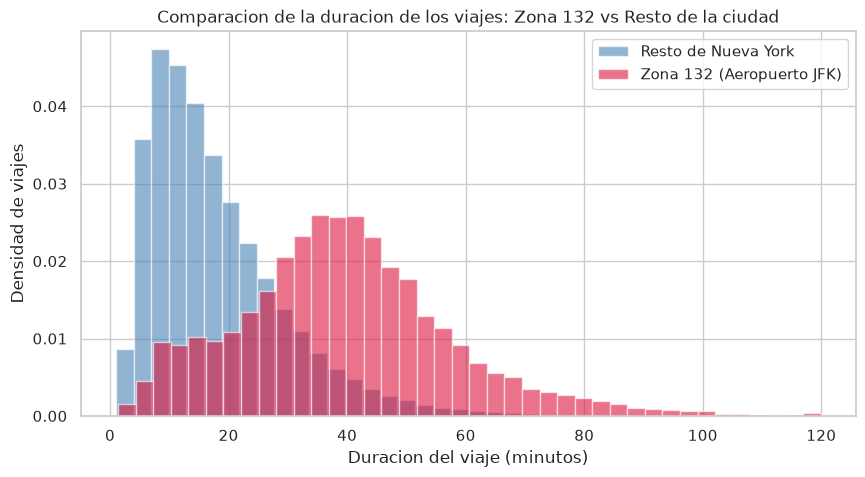

In [22]:
# elegimos la zona 132 que es la mas extrema en las graficas de PCA
zona_elegida = 132

# separamos los viajes que pasan por la zona 132 (como origen o destino) del resto de la ciudad
filtro_zona_132 = (tabla_viajes_taxis[columna_zona_recogida] == zona_elegida) | (tabla_viajes_taxis[columna_zona_destino] == zona_elegida)

viajes_zona_132 = tabla_viajes_taxis[filtro_zona_132]
viajes_resto_ciudad = tabla_viajes_taxis[~filtro_zona_132]

# imprimimos los datos principales de los dos grupos para compararlos
print(f"--- Resumen de la Zona {zona_elegida} ---")
print(f"Cantidad de viajes: {len(viajes_zona_132)}")
print(f"Duracion media: {viajes_zona_132['duracion_minutos'].mean():.2f} minutos")
print(f"Duracion mediana (50%): {viajes_zona_132['duracion_minutos'].median():.2f} minutos\n")

print("--- Resumen del resto de Nueva York ---")
print(f"Cantidad de viajes: {len(viajes_resto_ciudad)}")
print(f"Duracion media: {viajes_resto_ciudad['duracion_minutos'].mean():.2f} minutos")
print(f"Duracion mediana (50%): {viajes_resto_ciudad['duracion_minutos'].median():.2f} minutos")

# dibujamos un histograma superpuesto para ver la diferencia de tiempos a simple vista
plt.figure(figsize=(10, 5))
plt.hist(viajes_resto_ciudad["duracion_minutos"], bins=40, density=True, alpha=0.6, color="steelblue", label="Resto de Nueva York")
plt.hist(viajes_zona_132["duracion_minutos"], bins=40, density=True, alpha=0.6, color="crimson", label=f"Zona {zona_elegida} (Aeropuerto JFK)")

plt.title(f"Comparacion de la duracion de los viajes: Zona {zona_elegida} vs Resto de la ciudad")
plt.xlabel("Duracion del viaje (minutos)")
plt.ylabel("Densidad de viajes")
plt.legend()
plt.show()

### Conclusiones del estudio de la Zona 132 y cierre del ejercicio

Los numeros y la grafica confirman exactamente por que la red neuronal aislo la **Zona 132** tan lejos del resto en los graficos de PCA:
* Mientras que un viaje normal en el resto de Nueva York dura de media **18 minutos** (con una mediana de 15 minutos), los viajes que salen o llegan a la Zona 132 duran de media **39,5 minutos** (mas del doble).
* En el histograma se ve claramente como la distribucion de la Zona 132 esta completamente desplazada hacia la derecha, con muchisimos trayectos de entre 30 y 60 minutos.
* Al comprobar el mapa oficial de zonas de Nueva York, la Zona 132 corresponde al **Aeropuerto Internacional JFK**. Como esta situado lejos del centro (Manhattan), los trayectos son mucho mas largos y, por tanto, mas provechosos para los conductores.

En resumen, sin haberle dado ningun mapa ni coordenada geografica, los **embeddings** han sido capaces de aprender el comportamiento real de la ciudad solo a partir de la duracion de los viajes, agrupando los barrios urbanos normales en el centro y separando automaticamente los aeropuertos y salidas de la ciudad en los extremos.

### Uso de la IA en el desarrollo de la práctica

Durante el desarrollo de la práctica he utilizado la IA como apoyo para programar en Python. Principalmente, la he usado para resolver dudas, entender el funcionamiento de algunas librerías, corregir errores y consultar distintas formas de implementar determinadas funcionalidades.

También me ha servido para diseñar y ajustar la parte de las gráficas (como los histogramas de zonas, el etiquetado de los puntos más aislados en los gráficos de PCA en 2D y la comparativa de duraciones), así como para analizar los problemas que surgían al trabajar con los modelos y buscar posibles soluciones. Todas las propuestas que me daba las he ido revisando, adaptando y probando paso a paso para comprobar que realmente funcionaban en mi proyecto.